DATASET SOURCE:
https://www.who.int/data/gho/data/themes/air-pollution/who-air-quality-database

Note: This is a relevant reference source. The original source of the uploaded Excel file has not been verified.


Saving Air_Quality_Messy_and_Cleaned_Data.xlsx to Air_Quality_Messy_and_Cleaned_Data (1).xlsx

CLEANED AIR QUALITY DATASET


,Category,Item,Metric,Value,Unit,Source_Note
0,City air quality,Delhi,Average PM2.5,98,µg/m³,Illustrative figure for project
1,City air quality,Lucknow,Average PM2.5,85,µg/m³,Illustrative figure for project
2,City air quality,Kolkata,Average PM2.5,62,µg/m³,Illustrative figure for project
3,City air quality,Mumbai,Average PM2.5,45,µg/m³,Illustrative figure for project
4,City air quality,Chennai,Average PM2.5,35,µg/m³,Illustrative figure for project
5,City air quality,Bengaluru,Average PM2.5,30,µg/m³,Illustrative figure for project
6,Seasonal AQI,Winter,Average AQI,245,AQI index,Illustrative figure for project
7,Seasonal AQI,Post-monsoon,Average AQI,220,AQI index,Illustrative figure for project
8,Seasonal AQI,Summer,Average AQI,160,AQI index,Illustrative figure for project
9,Seasonal AQI,Monsoon,Average AQI,85,AQI index,Illustrative figure for project



Dataset Shape: (33, 6)

Column Names: ['Category', 'Item', 'Metric', 'Value', 'Unit', 'Source_Note']

Missing Values:
Category         0
Item             0
Metric           0
Value            0
Unit             0
Source_Note      0
Numeric_Value    6
dtype: int64

Duplicate Rows Remaining: 0

Cleaned Dataset:


,Category,Item,Metric,Value,Unit,Source_Note,Numeric_Value
0,City air quality,Delhi,Average PM2.5,98,µg/m³,Illustrative figure for project,98.0
1,City air quality,Lucknow,Average PM2.5,85,µg/m³,Illustrative figure for project,85.0
2,City air quality,Kolkata,Average PM2.5,62,µg/m³,Illustrative figure for project,62.0
3,City air quality,Mumbai,Average PM2.5,45,µg/m³,Illustrative figure for project,45.0
4,City air quality,Chennai,Average PM2.5,35,µg/m³,Illustrative figure for project,35.0
5,City air quality,Bengaluru,Average PM2.5,30,µg/m³,Illustrative figure for project,30.0
6,Seasonal AQI,Winter,Average AQI,245,AQI index,Illustrative figure for project,245.0
7,Seasonal AQI,Post-monsoon,Average AQI,220,AQI index,Illustrative figure for project,220.0
8,Seasonal AQI,Summer,Average AQI,160,AQI index,Illustrative figure for project,160.0
9,Seasonal AQI,Monsoon,Average AQI,85,AQI index,Illustrative figure for project,85.0



AIR QUALITY DATA SUMMARY
Total Records: 33
Total Categories: 6
Total Metrics: 6

Records by Category:


,Record Count
Category,
Monthly AQI,12
City air quality,6
AQI category,6
Seasonal AQI,4
WHO guideline,3
Health impact,2



Numeric Value Statistics:


,Numeric_Value
count,27.000000
mean,120.037037
std,87.262417
min,5.000000
25%,53.500000
50%,98.000000
75%,175.000000
max,290.000000


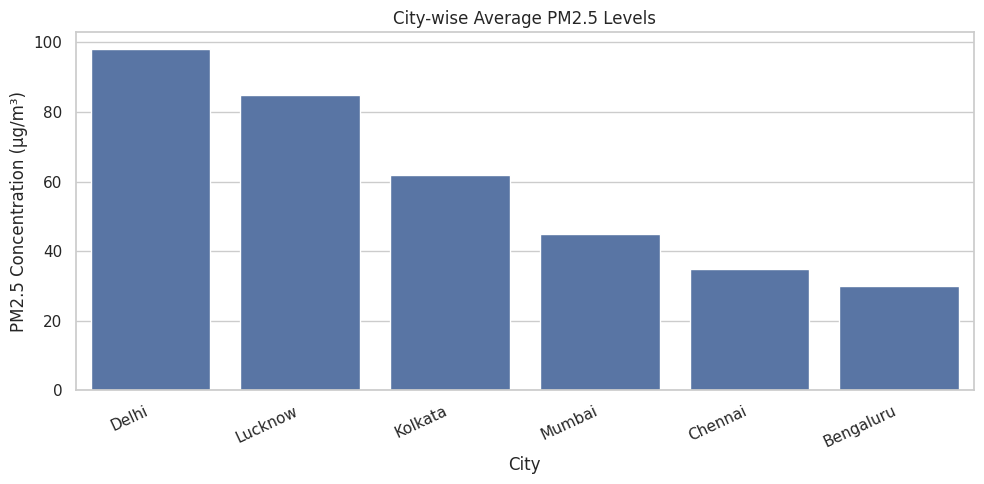

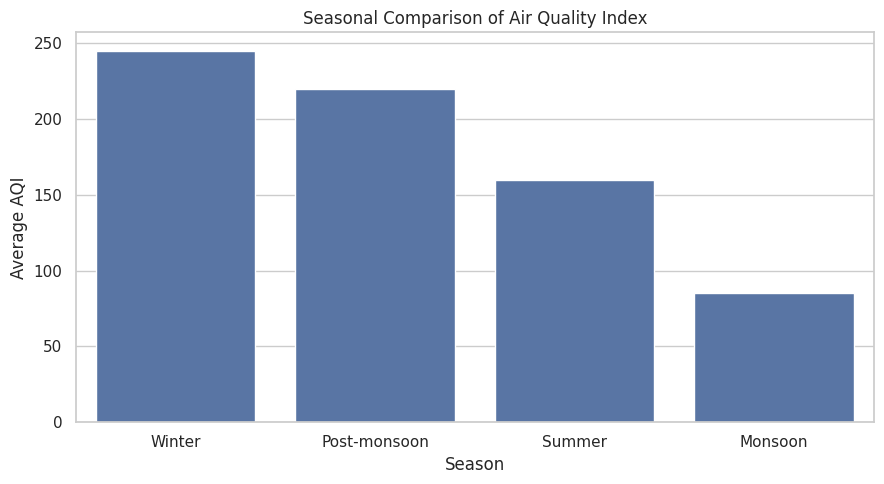

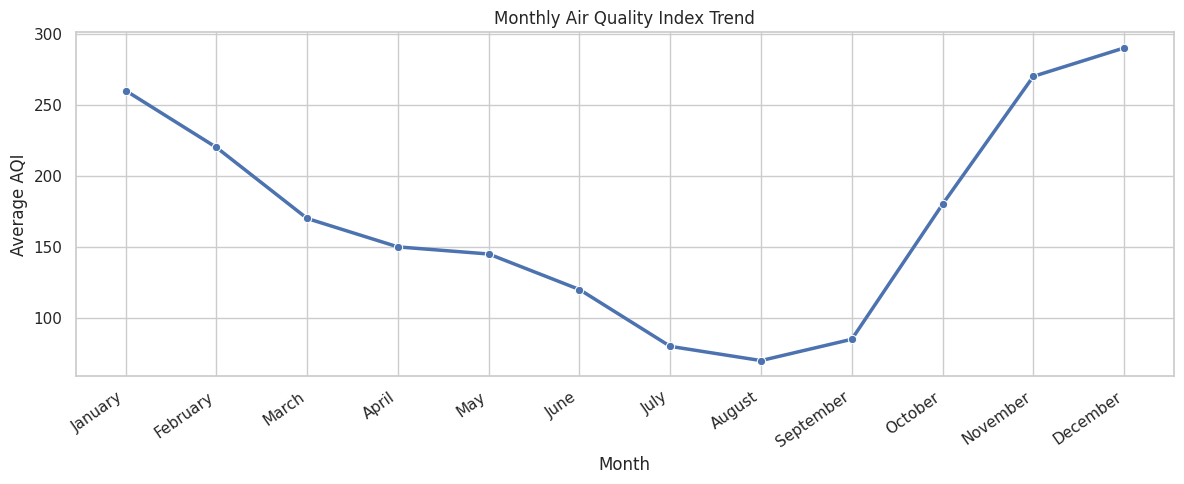

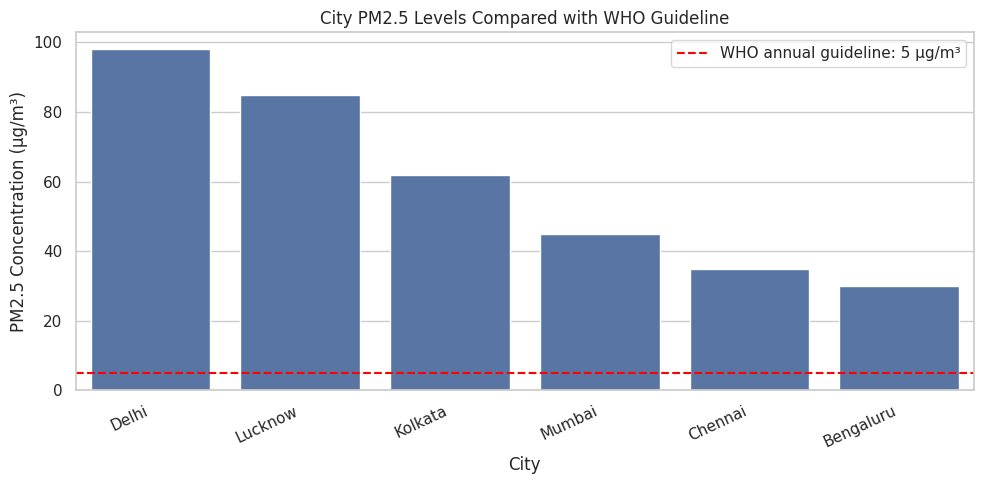

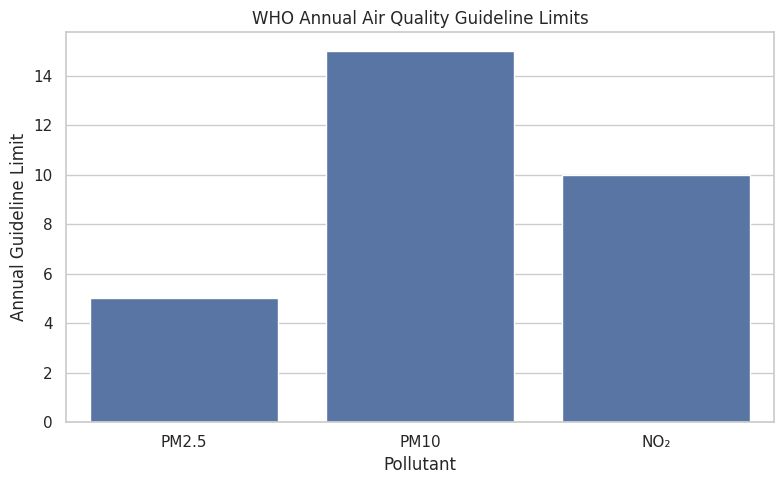


AQI CATEGORY REFERENCE:


,AQI Category,AQI Range,Unit


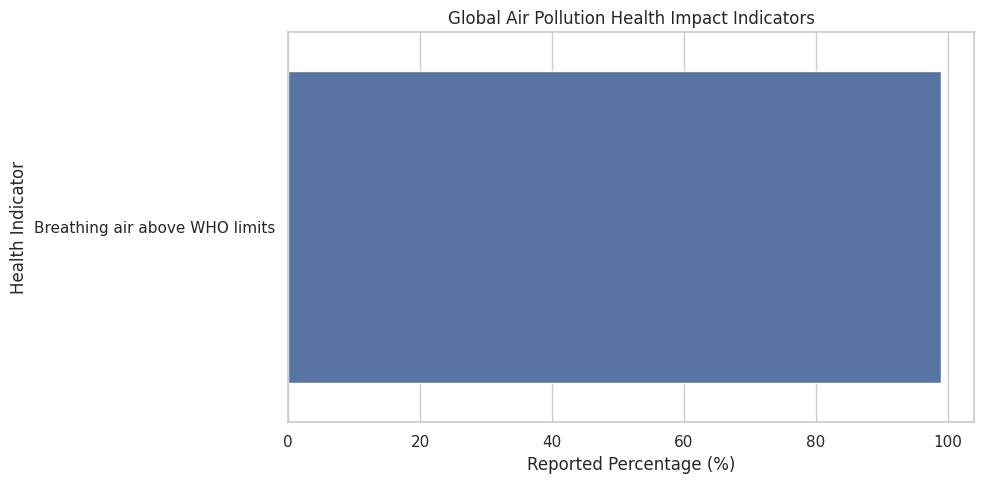


GLOBAL HEALTH IMPACT DATA:


,Metric,Value,Unit,Source_Note
31,Premature deaths per year linked to air pollution,7,million,WHO estimate (approx.)
32,Breathing air above WHO limits,99,percent,WHO estimate (approx.)



AIR QUALITY ANALYSIS COMPLETED
Total Records Analyzed: 33
Categories Analyzed: 6
Metrics Analyzed: 6

Highest PM2.5 in the dataset: Delhi - 98.0 µg/m³
Lowest PM2.5 in the dataset: Bengaluru - 30.0 µg/m³

Highest monthly AQI: December - 290.0
Lowest monthly AQI: August - 70.0

DATASET SOURCE:
https://www.who.int/data/gho/data/themes/air-pollution/who-air-quality-database

All visualizations and summary statistics generated.


In [2]:

# ============================================================
# SECTION 1: IMPORT REQUIRED LIBRARIES AND DATASET SOURCE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Official air quality dataset reference
DATASET_SOURCE = (
    "https://www.who.int/data/gho/data/themes/"
    "air-pollution/who-air-quality-database"
)

print("DATASET SOURCE:")
print(DATASET_SOURCE)
print("\nNote: This is a relevant reference source. "
      "The original source of the uploaded Excel file has not been verified.")


# ============================================================
# SECTION 2: UPLOAD AND READ THE CLEANED EXCEL DATASET
# ============================================================

uploaded = files.upload()
file_name = next(iter(uploaded))

# Read the cleaned dataset from the Excel file
df = pd.read_excel(file_name, sheet_name="Cleaned data")

print("\nCLEANED AIR QUALITY DATASET")
print("=" * 60)
display(df)

print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())


# ============================================================
# SECTION 3: DATA CLEANING AND VALIDATION
# ============================================================

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove unnecessary spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Convert Value to numeric where possible
df["Numeric_Value"] = pd.to_numeric(
    df["Value"], errors="coerce"
)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows Remaining:", df.duplicated().sum())

print("\nCleaned Dataset:")
display(df)


# ============================================================
# SECTION 4: SUMMARY STATISTICS
# ============================================================

print("\nAIR QUALITY DATA SUMMARY")
print("=" * 60)

print("Total Records:", len(df))
print("Total Categories:", df["Category"].nunique())
print("Total Metrics:", df["Metric"].nunique())

print("\nRecords by Category:")
display(
    df["Category"]
    .value_counts()
    .rename("Record Count")
    .to_frame()
)

print("\nNumeric Value Statistics:")
display(df["Numeric_Value"].describe().to_frame())


# ============================================================
# SECTION 5: CITY-WISE PM2.5 LEVELS
# ============================================================

# Compare average PM2.5 levels across cities
city = df[
    (df["Category"] == "City air quality") &
    (df["Metric"] == "Average PM2.5")
].copy()

city = city.dropna(subset=["Numeric_Value"])
city = city.sort_values("Numeric_Value", ascending=False)

if not city.empty:
    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=city,
        x="Item",
        y="Numeric_Value"
    )

    plt.title("City-wise Average PM2.5 Levels")
    plt.xlabel("City")
    plt.ylabel("PM2.5 Concentration (µg/m³)")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric city-wise PM2.5 data available.")


# ============================================================
# SECTION 6: SEASONAL AIR QUALITY INDEX (AQI)
# ============================================================

# Compare AQI across different seasons
season = df[
    (df["Category"] == "Seasonal AQI") &
    (df["Metric"] == "Average AQI")
].copy()

season = season.dropna(subset=["Numeric_Value"])
season = season.sort_values("Numeric_Value", ascending=False)

if not season.empty:
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=season,
        x="Item",
        y="Numeric_Value"
    )

    plt.title("Seasonal Comparison of Air Quality Index")
    plt.xlabel("Season")
    plt.ylabel("Average AQI")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric seasonal AQI data available.")


# ============================================================
# SECTION 7: MONTH-WISE AQI TREND
# ============================================================

# Display AQI changes throughout the year
month = df[
    (df["Category"] == "Monthly AQI") &
    (df["Metric"] == "Average AQI")
].copy()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

month["Item"] = pd.Categorical(
    month["Item"],
    categories=month_order,
    ordered=True
)

month = month.dropna(subset=["Numeric_Value"])
month = month.sort_values("Item")

if not month.empty:
    plt.figure(figsize=(12, 5))

    sns.lineplot(
        data=month,
        x="Item",
        y="Numeric_Value",
        marker="o",
        linewidth=2.5
    )

    plt.title("Monthly Air Quality Index Trend")
    plt.xlabel("Month")
    plt.ylabel("Average AQI")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric monthly AQI data available.")


# ============================================================
# SECTION 8: PM2.5 LEVELS VS WHO GUIDELINE
# ============================================================

# Compare city PM2.5 levels with the WHO annual guideline.
# The WHO annual PM2.5 guideline is 5 µg/m³ (2021 guidelines).
# This comparison is valid only if city values are annual averages.

who_limit = 5.0

if not city.empty:
    comparison = city.copy()

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=comparison,
        x="Item",
        y="Numeric_Value"
    )

    plt.axhline(
        y=who_limit,
        linestyle="--",
        color="red",
        label="WHO annual guideline: 5 µg/m³"
    )

    plt.title("City PM2.5 Levels Compared with WHO Guideline")
    plt.xlabel("City")
    plt.ylabel("PM2.5 Concentration (µg/m³)")
    plt.xticks(rotation=25, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.show()


# ============================================================
# SECTION 9: WHO ANNUAL AIR QUALITY GUIDELINE LIMITS
# ============================================================

# Display annual guideline limits supplied in the dataset
guidelines = df[
    (df["Category"] == "WHO guideline") &
    (df["Metric"] == "Annual guideline limit")
].copy()

guidelines = guidelines.dropna(subset=["Numeric_Value"])

if not guidelines.empty:
    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=guidelines,
        x="Item",
        y="Numeric_Value"
    )

    plt.title("WHO Annual Air Quality Guideline Limits")
    plt.xlabel("Pollutant")
    plt.ylabel("Annual Guideline Limit")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric annual guideline limits available.")


# ============================================================
# SECTION 10: AQI CATEGORY RANGES
# ============================================================

# Convert AQI range strings into numeric lower and upper limits
aqi_categories = df[
    (df["Category"] == "AQI category") &
    (df["Metric"] == "AQI range")
].copy()

if not aqi_categories.empty:
    ranges = aqi_categories["Value"].astype(str).str.extract(
        r"^\s*(\d+(?:\.\d+)?)\s*-\s*(\d+(?:\.\d+)?)\s*$"
    )

    aqi_categories["Range_Start"] = pd.to_numeric(
        ranges[0], errors="coerce"
    )

    aqi_categories["Range_End"] = pd.to_numeric(
        ranges[1], errors="coerce"
    )

    aqi_categories = aqi_categories.dropna(
        subset=["Range_Start", "Range_End"]
    )

    print("\nAQI CATEGORY REFERENCE:")
    display(
        aqi_categories[
            ["Item", "Value", "Unit"]
        ].rename(
            columns={
                "Item": "AQI Category",
                "Value": "AQI Range"
            }
        )
    )

    if not aqi_categories.empty:
        plt.figure(figsize=(10, 5))

        sns.barplot(
            data=aqi_categories,
            x="Item",
            y="Range_End"
        )

        plt.title("Upper AQI Limit by Air Quality Category")
        plt.xlabel("AQI Category")
        plt.ylabel("Upper AQI Limit")
        plt.xticks(rotation=25, ha="right")
        plt.tight_layout()
        plt.show()


# ============================================================
# SECTION 11: GLOBAL HEALTH IMPACT INDICATORS
# ============================================================

# Visualize reported global air pollution impact percentages
impact = df[
    (df["Category"] == "Health impact") &
    (df["Unit"] == "percent")
].copy()

impact = impact.dropna(subset=["Numeric_Value"])

if not impact.empty:
    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=impact,
        x="Numeric_Value",
        y="Metric"
    )

    plt.title("Global Air Pollution Health Impact Indicators")
    plt.xlabel("Reported Percentage (%)")
    plt.ylabel("Health Indicator")
    plt.tight_layout()
    plt.show()
else:
    print("No percentage-based health impact data available.")

# Display health impact records in their original units
print("\nGLOBAL HEALTH IMPACT DATA:")

health_columns = [
    col for col in
    ["Metric", "Value", "Unit", "Source_Note"]
    if col in df.columns
]

display(
    df[df["Category"] == "Health impact"][health_columns]
)


# ============================================================
# SECTION 12: FINAL PROJECT SUMMARY
# ============================================================

print("\nAIR QUALITY ANALYSIS COMPLETED")
print("=" * 60)

print("Total Records Analyzed:", len(df))
print("Categories Analyzed:", df["Category"].nunique())
print("Metrics Analyzed:", df["Metric"].nunique())

if not city.empty:
    highest_city = city.iloc[0]
    lowest_city = city.iloc[-1]

    print(
        "\nHighest PM2.5 in the dataset:",
        highest_city["Item"],
        "-",
        highest_city["Numeric_Value"],
        "µg/m³"
    )

    print(
        "Lowest PM2.5 in the dataset:",
        lowest_city["Item"],
        "-",
        lowest_city["Numeric_Value"],
        "µg/m³"
    )

if not month.empty:
    highest_month = month.loc[month["Numeric_Value"].idxmax()]
    lowest_month = month.loc[month["Numeric_Value"].idxmin()]

    print(
        "\nHighest monthly AQI:",
        highest_month["Item"],
        "-",
        highest_month["Numeric_Value"]
    )

    print(
        "Lowest monthly AQI:",
        lowest_month["Item"],
        "-",
        lowest_month["Numeric_Value"]
    )

print("\nDATASET SOURCE:")
print(DATASET_SOURCE)

print("\nAll visualizations and summary statistics generated.")
